In [26]:
#Imports 
import os
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from PIL import Image

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

from torchvision import transforms

from tqdm.auto import tqdm

In [27]:

#Paths registry 
PROJECT_ROOT = Path("/home/zahranadeem/thesis")

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

###############################################

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_attention_guided_sam2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)


Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt


In [28]:
#Checking the device 
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [29]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

DINO loaded.


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


In [30]:
import os

print(os.path.exists("/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment/TextToConcept.py"))

True


In [31]:
import sys

print("Python:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python:
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/bin/python

Python version:
3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]


In [32]:
import sys

!{sys.executable} -m pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-5gdxbql7
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-5gdxbql7


  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done


In [33]:
import clip

print("CLIP imported successfully")
print(clip.available_models())

CLIP imported successfully
['RN50', 'RN101', 'RN50x4', 'RN50x16', 'RN50x64', 'ViT-B/32', 'ViT-B/16', 'ViT-L/14', 'ViT-L/14@336px']


In [34]:
import sys
from pathlib import Path

ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

print("Python path:")
print(sys.path[0])

Python path:
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment


In [35]:
# ============================================================
# LOAD LINEAR ALIGNER MODULE
# ============================================================

import importlib.util
import sys
from pathlib import Path

# Path to LinearAligner.py
LINEAR_ALIGNER_PATH = (
    ALIGNMENT_DIR / "LinearAligner.py"
)

print(
    "LinearAligner path:",
    LINEAR_ALIGNER_PATH
)

print(
    "Exists:",
    LINEAR_ALIGNER_PATH.exists()
)

if not LINEAR_ALIGNER_PATH.exists():
    raise FileNotFoundError(
        f"LinearAligner.py not found at:\n"
        f"{LINEAR_ALIGNER_PATH}"
    )

# ------------------------------------------------------------
# Load module
# ------------------------------------------------------------

spec_linear = (
    importlib.util.spec_from_file_location(
        "LinearAligner",
        str(LINEAR_ALIGNER_PATH)
    )
)

if spec_linear is None or spec_linear.loader is None:
    raise ImportError(
        "Could not create import specification "
        "for LinearAligner.py"
    )

linear_module = (
    importlib.util.module_from_spec(
        spec_linear
    )
)

# Register module before executing it
sys.modules["LinearAligner"] = (
    linear_module
)

spec_linear.loader.exec_module(
    linear_module
)

# ------------------------------------------------------------
# Get class
# ------------------------------------------------------------

LinearAligner = (
    linear_module.LinearAligner
)

print(
    "\n✓ LinearAligner loaded successfully!"
)

print(
    "Class:",
    LinearAligner
)

print("=" * 70)

LinearAligner path: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment/LinearAligner.py
Exists: True

✓ LinearAligner loaded successfully!
Class: <class 'LinearAligner.LinearAligner'>


In [36]:
try:
    import clip
    print("CLIP is available!")
except ModuleNotFoundError:
    print("CLIP is NOT installed.")

CLIP is available!


In [37]:
import sys

!{sys.executable} -m pip install open_clip_torch

In [38]:
# ============================================================
# LOAD TEXTTOCONCEPT MODULE
# ============================================================

import importlib.util
import sys
from pathlib import Path

TEXT_TO_CONCEPT_PATH = (
    ALIGNMENT_DIR / "TextToConcept.py"
)

print(
    "TextToConcept path:",
    TEXT_TO_CONCEPT_PATH
)

print(
    "Exists:",
    TEXT_TO_CONCEPT_PATH.exists()
)

if not TEXT_TO_CONCEPT_PATH.exists():
    raise FileNotFoundError(
        f"TextToConcept.py not found at:\n"
        f"{TEXT_TO_CONCEPT_PATH}"
    )

# ------------------------------------------------------------
# Create import specification
# ------------------------------------------------------------

spec_text = (
    importlib.util.spec_from_file_location(
        "TextToConcept",
        str(TEXT_TO_CONCEPT_PATH)
    )
)

if spec_text is None or spec_text.loader is None:
    raise ImportError(
        "Could not create import specification "
        "for TextToConcept.py"
    )

# ------------------------------------------------------------
# Create module
# ------------------------------------------------------------

text_module = (
    importlib.util.module_from_spec(
        spec_text
    )
)

# Register before execution
sys.modules["TextToConcept"] = (
    text_module
)

# ------------------------------------------------------------
# Execute module
# ------------------------------------------------------------

spec_text.loader.exec_module(
    text_module
)

# ------------------------------------------------------------
# Get class
# ------------------------------------------------------------

TextToConcept = (
    text_module.TextToConcept
)

print(
    "\n✓ TextToConcept loaded successfully!"
)

print(
    "Class:",
    TextToConcept
)

print("=" * 70)

TextToConcept path: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment/TextToConcept.py
Exists: True

✓ TextToConcept loaded successfully!
Class: <class 'TextToConcept.TextToConcept'>


In [39]:
import sys

ALIGNMENT_DIR = "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
if ALIGNMENT_DIR not in sys.path:
    sys.path.append(ALIGNMENT_DIR)

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [40]:
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = text_to_concept.linear_aligner

print("VegAnn aligner loaded.")
print("W shape:", tuple(aligner.W.shape))
print("b shape:", tuple(aligner.b.shape))

VegAnn aligner loaded.
W shape: (512, 2048)
b shape: (512,)


In [41]:
#Register a hook on Dino layer4
captured_feature_map = None


def capture_layer4_output(module, inputs, output):
    global captured_feature_map
    captured_feature_map = output.detach()


hook_handle = dino_model.layer4.register_forward_hook(
    capture_layer4_output
)

print("DINO layer4 hook registered.")

DINO layer4 hook registered.


In [42]:
#Extract spatial DINO descriptors automatically wheter 7x7 or other
@torch.no_grad()
def extract_dino_patch_features(pil_image):
    
    

    global captured_feature_map

    captured_feature_map = None

    image_tensor = dino_transform(
        pil_image
    ).unsqueeze(0).to(device)

    _ = dino_model(image_tensor)

    if captured_feature_map is None:
        raise RuntimeError(
            "The layer4 hook did not capture a feature map."
        )

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected feature map shape (B, C, H, W), "
            f"but received {captured_feature_map.shape}."
        )

    _, channels, grid_h, grid_w = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(grid_h * grid_w, channels)
        .contiguous()
    )

    return patch_features, grid_h, grid_w

In [43]:


# ============================================================
# PPOSITIVE / NEGATIVE
# ============================================================

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil


In [44]:
@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)

# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])
Final vegetation embedding: torch.Size([512])


In [45]:
import sys
from pathlib import Path

ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

print(sys.path[0])

/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment


## RELEAF

In [46]:
from pathlib import Path


PROJECT_ROOT = Path("/home/zahranadeem/thesis")
RELEAF_ROOT = PROJECT_ROOT / "CropAndWeedAndLeaf"
RELEAF_REPO = PROJECT_ROOT / "releaf"

RELEAF_COCO_DIR = RELEAF_REPO / "data" / "CWL"
RELEAF_TEST_JSON = RELEAF_COCO_DIR / "annotations.json"

print("Project Layout Verified:")
print(f" • Project Directory:  {PROJECT_ROOT}")
print(f" • ReLeaf Benchmark:  {RELEAF_ROOT}")
print(f" • Git Code Repo:     {RELEAF_REPO}")
print(f" • Target COCO Path:  {RELEAF_TEST_JSON}")


Project Layout Verified:
 • Project Directory:  /home/zahranadeem/thesis
 • ReLeaf Benchmark:  /home/zahranadeem/thesis/CropAndWeedAndLeaf
 • Git Code Repo:     /home/zahranadeem/thesis/releaf
 • Target COCO Path:  /home/zahranadeem/thesis/releaf/data/CWL/annotations.json


In [47]:
# Completely wipe any previous files
import shutil


if RELEAF_ROOT.exists():
    shutil.rmtree(RELEAF_ROOT)
    print("Successfully cleaned up incomplete directory footprints.")
else:
    print(" Directory is already clean and clear.")


Successfully cleaned up incomplete directory footprints.


In [48]:
#Clone the official repository import os

import os

if not RELEAF_REPO.exists():
    print(" Cloning the official ReLeaf GitHub Repository...")
    !git clone https://github.com/cropandweed/releaf.git {str(RELEAF_REPO)}
else:
    print("ReLeaf repository codebase already exists locally.")


ReLeaf repository codebase already exists locally.


In [49]:
#Donload 
import urllib.request
import zipfile

ZIP_PATH = PROJECT_ROOT / "CropAndWeedAndLeaf.zip"
ZENODO_URL = "https://zenodo.org/records/20116408/files/CropAndWeedAndLeaf.zip"

# Fetch full database from Zenodo storage arrays
if not ZIP_PATH.exists():
    print("📡 Downloading full dataset package from Zenodo...")
    urllib.request.urlretrieve(ZENODO_URL, ZIP_PATH)
    print(" Download complete!")
else:
    print(" Raw dataset zip package already exists.")

print("Extracting complete dataset layers...")
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(RELEAF_ROOT)
print("Core archive files unpacked successfully!")


 Raw dataset zip package already exists.
Extracting complete dataset layers...
Core archive files unpacked successfully!


In [50]:
#Validate YOLOM raw files
images_dir = RELEAF_ROOT / "images"
labels_dir = RELEAF_ROOT / "labels"

if images_dir.exists() and labels_dir.exists():
    img_count = len(list(images_dir.glob("*")))
    print(f" Detected {img_count} baseline images ready for processing.")
else:
    print("Critical Warning: Missing image or label mapping locations.")


 Detected 345 baseline images ready for processing.


In [51]:
#Convert annotations 
#YOLO -> COCO and veridy 
import json
import cv2
from pathlib import Path
from tqdm import tqdm

# Ensure explicit path settings match your previous cells
PROJECT_ROOT = Path("/home/zahranadeem/thesis")
RELEAF_ROOT = PROJECT_ROOT / "CropAndWeedAndLeaf"
RELEAF_REPO = PROJECT_ROOT / "releaf"

# Target structure required by the evaluation frameworks
RELEAF_COCO_DIR = RELEAF_REPO / "data" / "CWL"
RELEAF_TEST_DIR = RELEAF_COCO_DIR / "test"
RELEAF_TEST_JSON = RELEAF_TEST_DIR / "_annotations.coco.json"

# Create evaluation target folders
RELEAF_TEST_DIR.mkdir(parents=True, exist_ok=True)

# Parse images directly out of downloaded workspace
images_src = RELEAF_ROOT / "images"
labels_src = RELEAF_ROOT / "labels"

# Standard COCO initialization parameters
coco_output = {
    "images": [],
    "annotations": [],
    "categories": [{"id": 1, "name": "leaf"}] # Unified single class structure
}

valid_extensions = ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.PNG")
image_files = []
for ext in valid_extensions:
    image_files.extend(list(images_src.glob(ext)))
image_files = sorted(image_files)

print(f" Parsing {len(image_files)} benchmark images into COCO instance layout...")
annotation_counter = 1

for img_id, img_path in enumerate(tqdm(image_files), start=1):
    # Read spatial canvas size dimensions
    img_cv = cv2.imread(str(img_path))
    if img_cv is None:
        continue
    h, w, _ = img_cv.shape
    
    # Symlink or copy images directly into the final test tracking folder
    target_img_path = RELEAF_TEST_DIR / img_path.name
    if not target_img_path.exists():
        target_img_path.symlink_to(img_path)
        
    coco_output["images"].append({
        "id": img_id,
        "file_name": img_path.name,
        "width": w,
        "height": h
    })
    
    # Process paired polygon coordinates labels file
    label_path = labels_src / f"{img_path.stem}.txt"
    if label_path.exists():
        with open(label_path, "r") as f:
            for line in f:
                elements = line.strip().split()
                if len(elements) < 5:
                    continue
                
                # Drop original class id arrays, force map to class index 1
                raw_coords = [float(x) for x in elements[1:]]
                
                # Check for segmentation polygon coordinates bounds
                if len(raw_coords) >= 6:
                    poly_canvas = []
                    for idx in range(0, len(raw_coords), 2):
                        poly_canvas.append(raw_coords[idx] * w)
                        poly_canvas.append(raw_coords[idx+1] * h)
                        
                    # Calculate strict bounding box coordinates fields [x, y, w, h]
                    x_coords = poly_canvas[0::2]
                    y_coords = poly_canvas[1::2]
                    min_x, max_x = min(x_coords), max(x_coords)
                    min_y, max_y = min(y_coords), max(y_coords)
                    bbox_width = max_x - min_x
                    bbox_height = max_y - min_y
                    
                    # Generate polygon contours area weight metrics
                    import numpy as np
                    contour_array = np.array(list(zip(x_coords, y_coords)), dtype=np.int32)
                    calculated_area = float(cv2.contourArea(contour_array))
                    
                    coco_output["annotations"].append({
                        "id": annotation_counter,
                        "image_id": img_id,
                        "category_id": 1,
                        "segmentation": [poly_canvas],
                        "bbox": [min_x, min_y, bbox_width, bbox_height],
                        "area": calculated_area,
                        "iscrowd": 0
                    })
                    annotation_counter += 1

# Write compiled target structures straight to disk
with open(RELEAF_TEST_JSON, "w") as json_file:
    json.dump(coco_output, json_file, indent=4)

print("\n Operation Completed Successfully!")
print(f" • File Created: {RELEAF_TEST_JSON.exists()}")
print(f" • Destination:  {RELEAF_TEST_JSON}")
print(f" • Images Saved: {len(coco_output['images'])} patches")
print(f" • Masks Linked: {len(coco_output['annotations'])} leaf instances")




 Parsing 345 benchmark images into COCO instance layout...


100%|██████████| 345/345 [00:00<00:00, 1269.80it/s]



 Operation Completed Successfully!
 • File Created: True
 • Destination:  /home/zahranadeem/thesis/releaf/data/CWL/test/_annotations.coco.json
 • Images Saved: 345 patches
 • Masks Linked: 3021 leaf instances


In [52]:
ZIP_PATH = (
    PROJECT_ROOT /
    "CropAndWeedAndLeaf.zip"
)

print(
    "ZIP exists:",
    ZIP_PATH.exists()
)

if ZIP_PATH.exists():
    print(
        "ZIP size:",
        ZIP_PATH.stat().st_size / (1024**3),
        "GB"
    )

ZIP exists: True
ZIP size: 0.01975090242922306 GB


In [53]:
matches = list(
    RELEAF_REPO.rglob("*.json")
)

print("JSON files found:", len(matches))

for p in matches[:50]:
    print(p)

JSON files found: 1
/home/zahranadeem/thesis/releaf/data/CWL/test/_annotations.coco.json


In [54]:
annotation_files = [
    p for p in RELEAF_REPO.rglob("*")
    if p.is_file()
    and "annotation" in p.name.lower()
]

print("\nAnnotation files:")

for p in annotation_files[:50]:
    print(p)


Annotation files:
/home/zahranadeem/thesis/releaf/data/CWL/test/_annotations.coco.json


In [55]:
CWL_DIR = RELEAF_REPO / "data" / "CWL"

print("CWL exists:", CWL_DIR.exists())

if CWL_DIR.exists():

    for item in CWL_DIR.iterdir():
        print(item)

CWL exists: True
/home/zahranadeem/thesis/releaf/data/CWL/train
/home/zahranadeem/thesis/releaf/data/CWL/valid
/home/zahranadeem/thesis/releaf/data/CWL/test


In [56]:
for name in ["train", "val", "test"]:

    matches = [
        p for p in RELEAF_REPO.rglob(name)
        if p.is_dir()
    ]

    print(f"\n{name.upper()} directories:")

    for p in matches:
        print(p)


TRAIN directories:
/home/zahranadeem/thesis/releaf/data/CWL/train

VAL directories:

TEST directories:
/home/zahranadeem/thesis/releaf/data/CWL/test


In [57]:
#starting with test, not creating own split 
import json
from pathlib import Path

RELEAF_TEST_DIR = (
    RELEAF_COCO_DIR / "test"
)

RELEAF_TEST_JSON = (
    RELEAF_TEST_DIR /
    "_annotations.coco.json"
)

print(RELEAF_TEST_DIR)
print(RELEAF_TEST_JSON)
print(RELEAF_TEST_JSON.exists())


/home/zahranadeem/thesis/releaf/data/CWL/test
/home/zahranadeem/thesis/releaf/data/CWL/test/_annotations.coco.json
True


In [58]:
#Load COCO annotations 
import json

with open(
    RELEAF_TEST_JSON,
    "r",
    encoding="utf-8"
) as f:

    releaf_coco = json.load(f)

print(
    "Images:",
    len(releaf_coco["images"])
)

print(
    "Annotations:",
    len(releaf_coco["annotations"])
)

print(
    "Categories:",
    releaf_coco["categories"]
)


Images: 345
Annotations: 3021
Categories: [{'id': 1, 'name': 'leaf'}]


In [59]:
#Create annotation lookup
from collections import defaultdict

releaf_annotations = defaultdict(list)

for ann in releaf_coco["annotations"]:

    image_id = ann["image_id"]

    releaf_annotations[
        image_id
    ].append(ann)

print(
    "Images with annotations:",
    len(releaf_annotations)
)

Images with annotations: 345


In [60]:
#Releaf image loader 
from PIL import Image

def get_releaf_image(index):

    info = releaf_coco["images"][index]

    image_path = (
        RELEAF_TEST_DIR /
        info["file_name"]
    )

    image = Image.open(
        image_path
    ).convert("RGB")

    return image, info

In [61]:
image, info = get_releaf_image(0)

print(
    "Image:",
    info["file_name"]
)

print(
    "Size:",
    image.size
)

Image: ave-0041-0002-002.jpg
Size: (231, 184)


In [62]:
#ReLeaf GT mask 
!!pip install pycocotools
from pycocotools import mask as mask_utils
import numpy as np


def get_releaf_mask(index):

    image_info = releaf_coco["images"][index]

    image_id = image_info["id"]

    height = image_info["height"]
    width = image_info["width"]

    binary_mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    anns = releaf_annotations.get(
        image_id,
        []
    )

    for ann in anns:

        segmentation = ann.get(
            "segmentation"
        )

        if segmentation is None:
            continue

        # Polygon segmentation
        if isinstance(
            segmentation,
            list
        ):

            rles = mask_utils.frPyObjects(
                segmentation,
                height,
                width
            )

            rle = mask_utils.merge(
                rles
            )

        # RLE segmentation
        else:

            rle = segmentation

            if isinstance(
                rle["counts"],
                str
            ):

                rle["counts"] = (
                    rle["counts"].encode(
                        "utf-8"
                    )
                )

        mask = mask_utils.decode(
            rle
        )

        if mask.ndim == 3:
            mask = np.any(
                mask,
                axis=2
            )

        binary_mask[
            mask > 0
        ] = 1

    return binary_mask

Image: (231, 184)
Mask: (184, 231)
Foreground: 16188


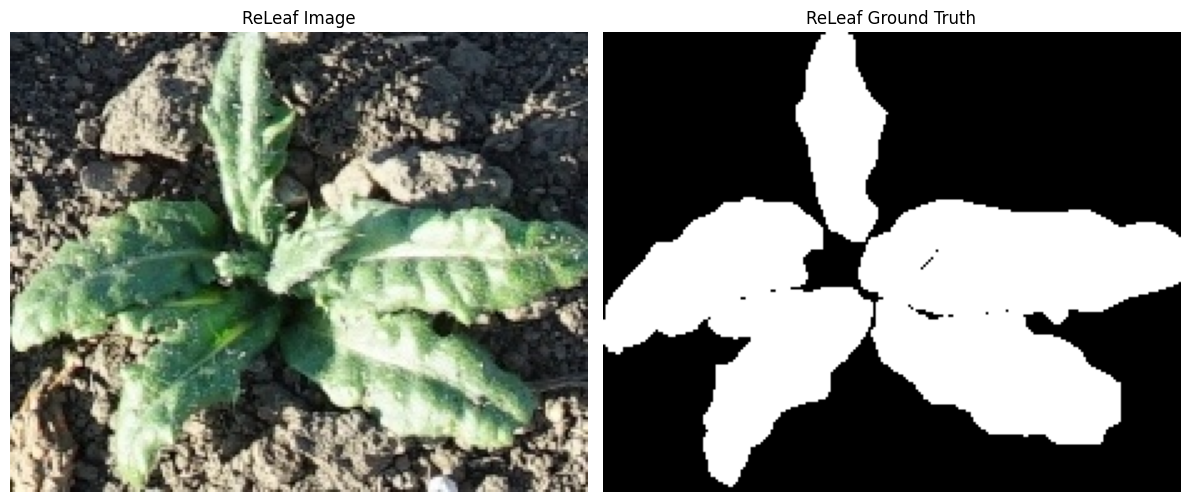

In [63]:
#Visualize 
import matplotlib.pyplot as plt

image, info = get_releaf_image(0)
releaf_gt = get_releaf_mask(0)

print("Image:", image.size)
print("Mask:", releaf_gt.shape)
print("Foreground:", releaf_gt.sum())

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(image)
plt.title("ReLeaf Image")
plt.axis("off")

plt.subplot(122)
plt.imshow(releaf_gt, cmap="gray")
plt.title("ReLeaf Ground Truth")
plt.axis("off")

plt.tight_layout()
plt.show()


In [64]:
from torchvision import transforms

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

print("DINO transform recreated.")

DINO transform recreated.


In [65]:
print(
    "DINO model exists:",
    "dino_model" in globals()
)

print(
    "DINO transform exists:",
    "dino_transform" in globals()
)

DINO model exists: True
DINO transform exists: True


In [66]:
#Create forward hook 
captured_feature_map = None

def capture_layer4_output(
    module,
    inputs,
    output
):
    global captured_feature_map
    captured_feature_map = output.detach()

hook_handle = (
    dino_model.layer4.register_forward_hook(
        capture_layer4_output
    )
)

print("DINO layer4 hook registered.")

DINO layer4 hook registered.


In [67]:
#Verify DINO extraction 
image, info = get_releaf_image(0)

patch_features, grid_h, grid_w = (
    extract_dino_patch_features(image)
)

print(
    "Feature grid:",
    grid_h,
    "x",
    grid_w
)

print(
    "Patch features:",
    patch_features.shape
)

Feature grid: 7 x 7
Patch features: torch.Size([49, 2048])


In [68]:
# Project DINO patches using the fine-tuned VegAnn aligner
# The projection maps DINO spatial features into the AgriCLIP concept space.
# Normalize only after the learned projection.

@torch.no_grad()
def align_patch_features(patch_features):

    patch_features = patch_features.float().to(device)

    aligned_features = aligner.get_aligned_representation(
        patch_features
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1,
    )

    return aligned_features

In [69]:
def generate_agriclip_box(
    image,
    top_k=32,
    margin=25
):

    # -----------------------------
    # DINO layer4 features
    # -----------------------------

    patch_features, grid_h, grid_w = (
        extract_dino_patch_features(
            image
        )
    )

    # -----------------------------
    # AgriCLIP alignment
    # -----------------------------

    aligned_features = (
        align_patch_features(
            patch_features
        )
    )

    # -----------------------------
    # Patch-text similarity
    # -----------------------------

    patch_scores = torch.matmul(
        aligned_features,
        vegetation_embedding
    )

    scores = (
        patch_scores
        .detach()
        .cpu()
        .numpy()
    )

    # -----------------------------
    # Top-K
    # -----------------------------

    topk_indices = np.argsort(
        scores
    )[::-1][:top_k]

    # -----------------------------
    # Convert patches to image boxes
    # -----------------------------

    H = image.size[1]
    W = image.size[0]

    patch_h = H / grid_h
    patch_w = W / grid_w

    boxes = []

    for idx in topk_indices:

        row = idx // grid_w
        col = idx % grid_w

        x1 = int(
            col * patch_w
        )

        y1 = int(
            row * patch_h
        )

        x2 = int(
            (col + 1) * patch_w
        )

        y2 = int(
            (row + 1) * patch_h
        )

        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )

    boxes = np.asarray(
        boxes,
        dtype=np.int32
    )

    # -----------------------------
    # Merge selected boxes
    # -----------------------------

    xmin = boxes[:, 0].min()
    ymin = boxes[:, 1].min()

    xmax = boxes[:, 2].max()
    ymax = boxes[:, 3].max()

    # -----------------------------
    # Add same 25-pixel margin
    # -----------------------------

    xmin = max(
        0,
        xmin - margin
    )

    ymin = max(
        0,
        ymin - margin
    )

    xmax = min(
        W - 1,
        xmax + margin
    )

    ymax = min(
        H - 1,
        ymax + margin
    )

    agriclip_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )

    return (
        agriclip_box,
        boxes,
        scores,
        topk_indices
    )

In [70]:
#Test box generation 
image, info = get_releaf_image(0)

releaf_gt = get_releaf_mask(0)

agriclip_box, boxes, scores, topk_indices = (
    generate_agriclip_box(
        image,
        top_k=8,
        margin=25
    )
)

print(
    "AgriCLIP box:",
    agriclip_box
)

print(
    "Top-K indices:",
    topk_indices
)

print(
    "Top-K scores:",
    scores[topk_indices]
)

AgriCLIP box: [  0   0 230 183]
Top-K indices: [32 15 46 21  2 45 20 43]
Top-K scores: [0.11015145 0.10882696 0.10345611 0.10024721 0.09266274 0.09230313
 0.09032211 0.08654572]


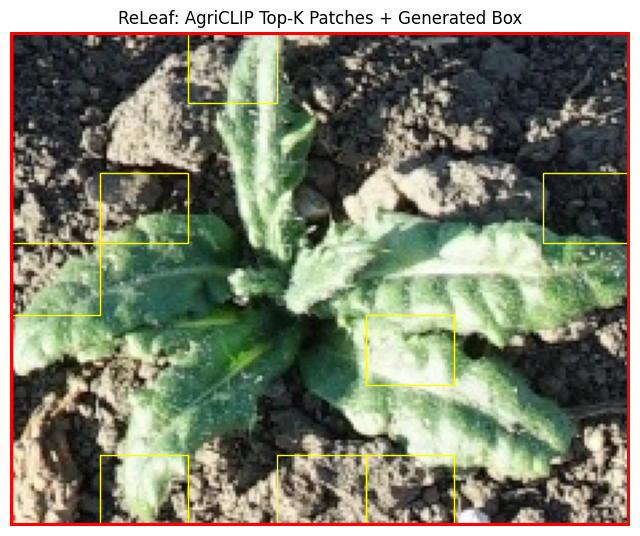

In [71]:
#Visualize the generated box 
import matplotlib.patches as patches

fig, ax = plt.subplots(
    figsize=(8, 8)
)

ax.imshow(image)

# Individual selected patches

for box in boxes:

    x1, y1, x2, y2 = box

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="yellow",
        linewidth=1
    )

    ax.add_patch(rect)


# Final merged box

x1, y1, x2, y2 = agriclip_box

rect = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    fill=False,
    edgecolor="red",
    linewidth=3
)

ax.add_patch(rect)

ax.set_title(
    "ReLeaf: AgriCLIP Top-K Patches + Generated Box"
)

ax.axis("off")

plt.show()

In [72]:
#Load fine tuned SAM2 model 
sam2_processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

sam2_model = Sam2Model.from_pretrained(
    MODEL_NAME
)

sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu",
)

print("SAM2 checkpoint type:", type(sam2_checkpoint))

if (
    isinstance(sam2_checkpoint, dict)
    and "mask_decoder_state_dict" in sam2_checkpoint
):
    mask_decoder_state_dict = sam2_checkpoint[
        "mask_decoder_state_dict"
    ]
elif isinstance(sam2_checkpoint, dict):
    # Supports a checkpoint that directly contains decoder weights.
    mask_decoder_state_dict = sam2_checkpoint
else:
    raise TypeError(
        "Unsupported SAM2 checkpoint structure."
    )

load_result = sam2_model.mask_decoder.load_state_dict(
    mask_decoder_state_dict,
    strict=True,
)

sam2_model = sam2_model.to(device)
sam2_model.eval()

print("Fine-tuned SAM2 mask decoder loaded.")
print(load_result)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 checkpoint type: <class 'dict'>
Fine-tuned SAM2 mask decoder loaded.
<All keys matched successfully>


In [73]:
@torch.no_grad()
def sam2_predict_box(
    image,
    input_box,
    threshold=0.5
):

    sam2_inputs = sam2_processor(
        images=image,
        input_boxes=[
            [input_box.tolist()]
        ],
        return_tensors="pt"
    )

    sam2_inputs = {
        k: v.to(device)
        if torch.is_tensor(v)
        else v
        for k, v in sam2_inputs.items()
    }

    sam2_outputs = sam2_model(
        **sam2_inputs
    )

    # Select best candidate
    best_candidate_index = int(
        sam2_outputs
        .iou_scores[0, 0]
        .argmax()
        .item()
    )

    best_logits = (
        sam2_outputs.pred_masks[
            0,
            0,
            best_candidate_index
        ]
    )

    probability = torch.sigmoid(
        best_logits
    )

    original_height = int(
        sam2_inputs[
            "original_sizes"
        ][0, 0].item()
    )

    original_width = int(
        sam2_inputs[
            "original_sizes"
        ][0, 1].item()
    )

    probability = F.interpolate(
        probability[None, None],
        size=(
            original_height,
            original_width
        ),
        mode="bilinear",
        align_corners=False
    )[0, 0]

    prediction = (
        probability >= threshold
    ).cpu().numpy().astype(
        np.uint8
    )

    confidence = float(
        sam2_outputs
        .iou_scores[
            0,
            0,
            best_candidate_index
        ]
        .item()
    )

    return (
        prediction,
        probability.cpu().numpy(),
        confidence
    )

In [74]:
#Run on Releaf image 
pred_mask, probability, confidence = (
    sam2_predict_box(
        image,
        agriclip_box,
        threshold=0.5
    )
)

print(
    "Prediction shape:",
    pred_mask.shape
)

print(
    "GT shape:",
    releaf_gt.shape
)

print(
    "SAM2 confidence:",
    confidence
)#Define segmentation metrics 
def compute_binary_metrics(prediction, ground_truth):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(
        prediction,
        ground_truth,
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth,
    ).sum()

    pred_pixels = prediction.sum()
    gt_pixels = ground_truth.sum()

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    dice_denominator = pred_pixels + gt_pixels

    dice = (
        2.0 * intersection / dice_denominator
        if dice_denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "intersection": int(intersection),
        "union": int(union),
        "pred_pixels": int(pred_pixels),
        "gt_pixels": int(gt_pixels),
    }


metrics = compute_binary_metrics(
    pred_mask,
    releaf_gt,
)

for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name:>14}: {value:.4f}")
    else:
        print(f"{name:>14}: {value}")

Prediction shape: (184, 231)
GT shape: (184, 231)
SAM2 confidence: 0.9571020603179932
           iou: 0.9054
          dice: 0.9503
     precision: 0.9072
        recall: 0.9978
  intersection: 16152
         union: 17840
   pred_pixels: 17804
     gt_pixels: 16188


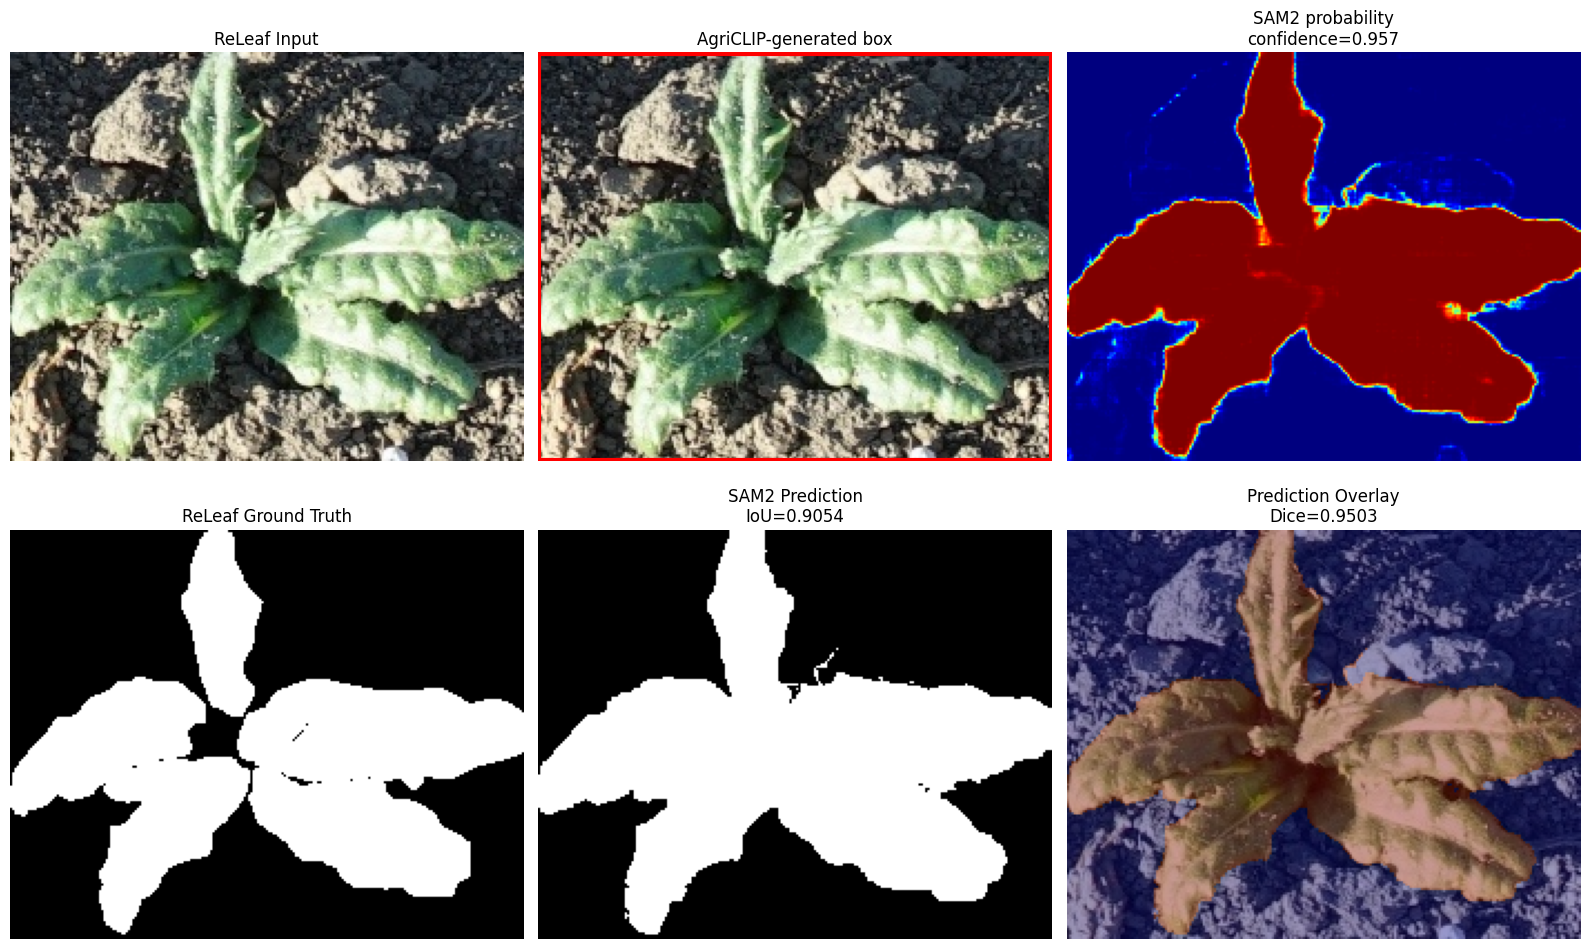

In [75]:
#Viuslize 
fig, ax = plt.subplots(
    2,
    3,
    figsize=(16, 10)
)

# Input
ax[0, 0].imshow(image)
ax[0, 0].set_title("ReLeaf Input")
ax[0, 0].axis("off")

# AgriCLIP box
ax[0, 1].imshow(image)

x1, y1, x2, y2 = agriclip_box

ax[0, 1].add_patch(
    plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="red",
        linewidth=3
    )
)

ax[0, 1].set_title(
    "AgriCLIP-generated box"
)

ax[0, 1].axis("off")

# Probability
ax[0, 2].imshow(
    probability,
    cmap="jet"
)

ax[0, 2].set_title(
    f"SAM2 probability\n"
    f"confidence={confidence:.3f}"
)

ax[0, 2].axis("off")

# GT
ax[1, 0].imshow(
    releaf_gt,
    cmap="gray"
)

ax[1, 0].set_title(
    "ReLeaf Ground Truth"
)

ax[1, 0].axis("off")

# Prediction
ax[1, 1].imshow(
    pred_mask,
    cmap="gray"
)

ax[1, 1].set_title(
    f"SAM2 Prediction\n"
    f"IoU={metrics['iou']:.4f}"
)

ax[1, 1].axis("off")

# Overlay
ax[1, 2].imshow(image)

ax[1, 2].imshow(
    pred_mask,
    cmap="jet",
    alpha=0.4
)

ax[1, 2].set_title(
    f"Prediction Overlay\n"
    f"Dice={metrics['dice']:.4f}"
)

ax[1, 2].axis("off")

plt.tight_layout()
plt.show()

In [76]:
#Full Releaf test evaluation 
releaf_results = []

num_images = len(
    releaf_coco["images"]
)

print(
    "ReLeaf test images:",
    num_images
)

ReLeaf test images: 345


In [ ]:
# ============================================================
# RELEAF — CHECK FOR EMPTY GROUND-TRUTH MASKS
# ============================================================

empty_releaf_indices = []
nonempty_releaf_indices = []

foreground_counts = []

for idx in tqdm(
    range(len(releaf_coco["images"])),
    desc="Checking ReLeaf GT masks"
):

    gt_mask = get_releaf_mask(idx)

    foreground_pixels = int(
        gt_mask.sum()
    )

    foreground_counts.append(
        foreground_pixels
    )

    if foreground_pixels == 0:

        empty_releaf_indices.append(idx)

    else:

        nonempty_releaf_indices.append(idx)


print("\n")
print("=" * 70)
print("RELEAF GT MASK DIAGNOSTIC")
print("=" * 70)

print(
    "Total ReLeaf images:",
    len(releaf_coco["images"])
)

print(
    "Non-empty GT masks:",
    len(nonempty_releaf_indices)
)

print(
    "Empty GT masks:",
    len(empty_releaf_indices)
)

print(
    "Empty percentage:",
    f"{100 * len(empty_releaf_indices) / len(releaf_coco['images']):.2f}%"
)

print(
    "\nEmpty image indices:"
)

print(
    empty_releaf_indices
)

if foreground_counts:

    print(
        "\nMinimum foreground pixels:",
        min(foreground_counts)
    )

    print(
        "Maximum foreground pixels:",
        max(foreground_counts)
    )

print("=" * 70)

In [84]:
# ============================================================
# RELEAF — FULL AGRICLIP + SAM2 EVALUATION
# K = 32 | Margin = 25 | Threshold = 0.5
# ============================================================

releaf_results = []

empty_gt_count = 0
failed_count = 0

for idx in tqdm(
    range(num_images),
    desc="Evaluating ReLeaf"
):

    try:

        # ----------------------------------------------------
        # Load image
        # ----------------------------------------------------

        image, info = get_releaf_image(idx)

        # ----------------------------------------------------
        # Ground truth
        # ----------------------------------------------------

        gt_mask = get_releaf_mask(idx)

        # ----------------------------------------------------
        # Skip empty annotations
        # ----------------------------------------------------

        if gt_mask.sum() == 0:

            empty_gt_count += 1
            continue

        # ----------------------------------------------------
        # AgriCLIP box
        # ----------------------------------------------------

        (
            agriclip_box,
            boxes,
            scores,
            topk_indices
        ) = generate_agriclip_box(
            image,
            top_k=32,
            margin=25
        )

        # ----------------------------------------------------
        # SAM2
        # ----------------------------------------------------

        (
            pred_mask,
            probability,
            confidence
        ) = sam2_predict_box(
            image,
            agriclip_box,
            threshold=0.5
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        metrics = compute_binary_metrics(
            pred_mask,
            gt_mask
        )

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        releaf_results.append({
            "image_id":
                info["id"],

            "file_name":
                info["file_name"],

            "iou":
                metrics["iou"],

            "dice":
                metrics["dice"],

            "precision":
                metrics["precision"],

            "recall":
                metrics["recall"],

            "sam2_confidence":
                confidence,

            "box_x1":
                int(agriclip_box[0]),

            "box_y1":
                int(agriclip_box[1]),

            "box_x2":
                int(agriclip_box[2]),

            "box_y2":
                int(agriclip_box[3]),

            "top_k":
                32,

            "margin":
                25,

            "threshold":
                0.5
        })

    except Exception as e:

        failed_count += 1

        print(
            f"\nError at index {idx}: {e}"
        )

        continue


# ============================================================
# CONVERT TO DATAFRAME
# ============================================================

releaf_df = pd.DataFrame(
    releaf_results
)


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("RELEAF — AGRICLIP + SAM2 RESULTS")
print("=" * 70)

print(
    f"Total images:            {num_images}"
)

print(
    f"Successful evaluations:  {len(releaf_df)}"
)

print(
    f"Empty GT images skipped: {empty_gt_count}"
)

print(
    f"Failed images:           {failed_count}"
)

if len(releaf_df) > 0:

    mean_iou = (
        releaf_df["iou"].mean()
    )

    mean_dice = (
        releaf_df["dice"].mean()
    )

    mean_precision = (
        releaf_df["precision"].mean()
    )

    mean_recall = (
        releaf_df["recall"].mean()
    )

    mean_confidence = (
        releaf_df["sam2_confidence"].mean()
    )

    print("\n")
    print(
        f"Mean IoU:        "
        f"{mean_iou:.4f} "
        f"({mean_iou * 100:.2f}%)"
    )

    print(
        f"Mean Dice:       "
        f"{mean_dice:.4f} "
        f"({mean_dice * 100:.2f}%)"
    )

    print(
        f"Mean Precision:  "
        f"{mean_precision:.4f} "
        f"({mean_precision * 100:.2f}%)"
    )

    print(
        f"Mean Recall:     "
        f"{mean_recall:.4f} "
        f"({mean_recall * 100:.2f}%)"
    )

    print(
        f"Mean Confidence: "
        f"{mean_confidence:.4f}"
    )

else:

    print(
        "\nNo valid evaluations were completed."
    )

print("=" * 70)

Evaluating ReLeaf:   1%|          | 4/345 [00:00<00:10, 32.52it/s]

Evaluating ReLeaf: 100%|██████████| 345/345 [00:09<00:00, 34.79it/s]



RELEAF — AGRICLIP + SAM2 RESULTS
Total images:            345
Successful evaluations:  345
Empty GT images skipped: 0
Failed images:           0


Mean IoU:        0.8010 (80.10%)
Mean Dice:       0.8833 (88.33%)
Mean Precision:  0.8137 (81.37%)
Mean Recall:     0.9796 (97.96%)
Mean Confidence: 0.9608


In [85]:
#Results Dataframe 
import pandas as pd

releaf_df = pd.DataFrame(
    releaf_results
)

print(
    "Successful evaluations:",
    len(releaf_df)
)

display(
    releaf_df.head()
)

print(
    releaf_df[
        [
            "iou",
            "dice",
            "precision",
            "recall",
            "sam2_confidence"
        ]
    ].isna().sum()
)

Successful evaluations: 345


,image_id,file_name,iou,dice,precision,recall,sam2_confidence,box_x1,box_y1,box_x2,box_y2,top_k,margin,threshold
0,1,ave-0041-0002-002.jpg,0.905381,0.950341,0.907212,0.997776,0.957102,0,0,230,183,32,25,0.5
1,2,ave-0045-0011-012.jpg,0.641454,0.781568,0.650699,0.978330,0.933554,0,0,195,155,32,25,0.5
2,3,ave-0048-0002-026.jpg,0.908905,0.952279,0.933002,0.972368,0.951947,0,0,145,127,32,25,0.5
3,4,ave-0048-0006-031.jpg,0.785834,0.880075,0.792239,0.989817,0.974953,0,0,152,138,32,25,0.5
4,5,ave-0048-0019-037.jpg,0.884660,0.938801,0.894189,0.988098,0.970728,0,0,137,130,32,25,0.5


iou                0
dice               0
precision          0
recall             0
sam2_confidence    0
dtype: int64


In [86]:
# ============================================================
# RELEAF RESULTS SUMMARY
# ============================================================

releaf_summary = pd.DataFrame({
    "Dataset": ["ReLeaf"],
    "Method": ["SAM2 + AgriCLIP Box"],
    "Images Evaluated": [len(releaf_df)],
    "Mean IoU (%)": [
        releaf_df["iou"].mean() * 100
    ],
    "Mean Dice (%)": [
        releaf_df["dice"].mean() * 100
    ],
    "Mean Precision (%)": [
        releaf_df["precision"].mean() * 100
    ],
    "Mean Recall (%)": [
        releaf_df["recall"].mean() * 100
    ],
    "Mean SAM2 Confidence": [
        releaf_df["sam2_confidence"].mean()
    ],
})

releaf_summary = releaf_summary.round(4)

display(releaf_summary)

,Dataset,Method,Images Evaluated,Mean IoU (%),Mean Dice (%),Mean Precision (%),Mean Recall (%),Mean SAM2 Confidence
0,ReLeaf,SAM2 + AgriCLIP Box,345,80.0956,88.3322,81.3744,97.9616,0.9608


In [ ]:
releaf_iou = (
    releaf_results["iou"].dropna() * 100
)

releaf_dice = (
    releaf_results["dice"].dropna() * 100
)

plt.figure(figsize=(8, 6))

plt.boxplot(
    [
        releaf_iou,
        releaf_dice
    ],
    labels=[
        "IoU",
        "Dice"
    ]
)

plt.ylabel("Score (%)")
plt.title(
    "ReLeaf Test Set: IoU and Dice Distribution"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

Evaluating ReLeaf: 100%|██████████| 345/345 [00:10<00:00, 34.08it/s]



RELEAF — AGRICLIP + SAM2 RESULTS
Total images:            345
Successful evaluations:  345
Empty GT images skipped: 0
Failed images:           0


Mean IoU:        0.8010 (80.10%)
Mean Dice:       0.8833 (88.33%)
Mean Precision:  0.8137 (81.37%)
Mean Recall:     0.9796 (97.96%)
Mean Confidence: 0.9608


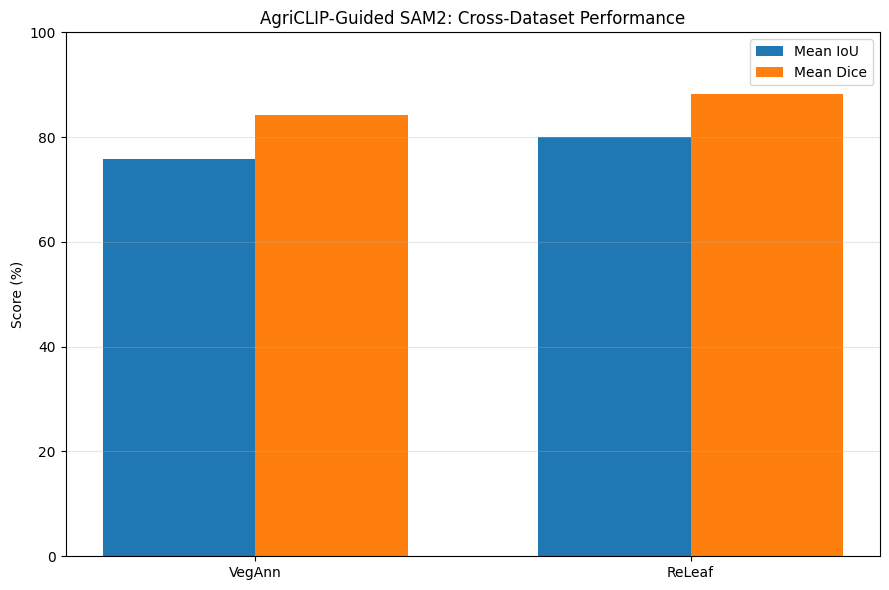

In [ ]:
datasets = [
    "VegAnn",
    "ReLeaf"
]

iou_values = [
    75.85,
    80.0396
]

dice_values = [
    84.30,
    88.2857
]

x = np.arange(len(datasets))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    iou_values,
    width,
    label="Mean IoU"
)

plt.bar(
    x + width / 2,
    dice_values,
    width,
    label="Mean Dice"
)

plt.xticks(x, datasets)

plt.ylabel("Score (%)")
plt.title(
    "AgriCLIP-Guided SAM2: Cross-Dataset Performance"
)

plt.ylim(0, 100)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [87]:
# ============================================================
# RELEAF K ABLATION — MERGED BOX
# ============================================================

K_VALUES = [
    4,
    8,
    12,
    16,
    20,
    24,
    28,
    32,
    40,
    49
]

k_results = []

for K_TEST in K_VALUES:

    print(
        f"\nEvaluating ReLeaf K={K_TEST}"
    )

    image_results = []

    for idx in tqdm(
        range(num_images),
        desc=f"ReLeaf K={K_TEST}"
    ):

        try:

            image, info = (
                get_releaf_image(idx)
            )

            gt_mask = (
                get_releaf_mask(idx)
            )

            if gt_mask.sum() == 0:
                continue

            # ----------------------------------------------
            # AgriCLIP merged box
            # ----------------------------------------------

            (
                agriclip_box,
                boxes,
                scores,
                topk_indices
            ) = generate_agriclip_box(
                image,
                top_k=K_TEST,
                margin=25
            )

            # ----------------------------------------------
            # SAM2
            # ----------------------------------------------

            (
                pred_mask,
                probability,
                confidence
            ) = sam2_predict_box(
                image,
                agriclip_box,
                threshold=0.5
            )

            # ----------------------------------------------
            # Metrics
            # ----------------------------------------------

            metrics = compute_binary_metrics(
                pred_mask,
                gt_mask
            )

            # ----------------------------------------------
            # Box area
            # ----------------------------------------------

            W, H = image.size

            box_width = (
                agriclip_box[2]
                - agriclip_box[0]
                + 1
            )

            box_height = (
                agriclip_box[3]
                - agriclip_box[1]
                + 1
            )

            box_area_percent = (
                box_width
                * box_height
                /
                (W * H)
                * 100
            )

            image_results.append({

                "iou":
                    metrics["iou"],

                "dice":
                    metrics["dice"],

                "precision":
                    metrics["precision"],

                "recall":
                    metrics["recall"],

                "confidence":
                    confidence,

                "box_area_percent":
                    box_area_percent
            })

        except Exception as e:

            print(
                f"\nError at {idx}: {e}"
            )

    if len(image_results) == 0:
        continue

    df_k = pd.DataFrame(
        image_results
    )

    k_results.append({

        "K":
            K_TEST,

        "images":
            len(df_k),

        "mean_box_area_percent":
            df_k[
                "box_area_percent"
            ].mean(),

        "iou":
            df_k["iou"].mean(),

        "dice":
            df_k["dice"].mean(),

        "precision":
            df_k["precision"].mean(),

        "recall":
            df_k["recall"].mean(),

        "sam2_confidence":
            df_k[
                "confidence"
            ].mean()
    })


releaf_k_df = pd.DataFrame(
    k_results
)

print("\n")
print("=" * 70)
print("RELEAF K ABLATION — MERGED BOX")
print("=" * 70)

display(
    releaf_k_df.style.format({
        "mean_box_area_percent":
            "{:.2f}",

        "iou":
            "{:.4f}",

        "dice":
            "{:.4f}",

        "precision":
            "{:.4f}",

        "recall":
            "{:.4f}",

        "sam2_confidence":
            "{:.4f}"
    })
)


Evaluating ReLeaf K=4


ReLeaf K=4: 100%|██████████| 345/345 [00:10<00:00, 34.01it/s]



Evaluating ReLeaf K=8


ReLeaf K=8: 100%|██████████| 345/345 [00:09<00:00, 34.91it/s]



Evaluating ReLeaf K=12


ReLeaf K=12: 100%|██████████| 345/345 [00:09<00:00, 34.74it/s]


... (12 outputs left out)


Evaluating ReLeaf K=49


ReLeaf K=49: 100%|██████████| 345/345 [00:09<00:00, 34.65it/s]



RELEAF K ABLATION — MERGED BOX


,K,images,mean_box_area_percent,iou,dice,precision,recall,sam2_confidence
0,4,345,72.81,0.7977,0.8810,0.8260,0.9582,0.9598
1,8,345,92.51,0.8006,0.8832,0.8171,0.9747,0.9608
2,12,345,97.65,0.8011,0.8834,0.8148,0.9783,0.9609
3,16,345,99.33,0.8009,0.8833,0.8140,0.9791,0.9608
4,20,345,99.72,0.8010,0.8834,0.8139,0.9796,0.9608
5,24,345,99.88,0.8010,0.8833,0.8138,0.9796,0.9608
6,28,345,99.96,0.8010,0.8833,0.8138,0.9796,0.9608
7,32,345,99.98,0.8010,0.8833,0.8137,0.9796,0.9608
8,40,345,100.00,0.8010,0.8833,0.8137,0.9796,0.9608
9,49,345,100.00,0.8010,0.8833,0.8137,0.9796,0.9608
